# Replicating Goldrick et al. (2015) with Penicillium

> S. Goldrick, A. Ştefan, D. Lovett, G. Montague, B. Lennox. *The development of an industrial-scale fed-batch
> fermentation simulation.* Journal of Biotechnology 193 (2015) 70-82.
> [doi:10.1016/j.jbiotec.2014.10.029](https://doi.org/10.1016/j.jbiotec.2014.10.029) (accepted manuscript in `docs/`).

This paper introduces the IndPenSim model and validates it against the batch records of ten 100 m³ industrial
penicillin fermentations (its Table 3). For each batch it fed the **recorded** manipulated variables (sugar, oil,
water, aeration, back pressure and discharge, sampled hourly) into the simulation and compared the outputs with
the plant measurements (Figs. 3-5).

**What can and cannot be replicated.** The plant records are confidential and not published, so the exact
validation cannot be repeated. What we can do:

* simulate the ten batches of Table 3 with their published batch lengths and maximum specific growth and
  production rates ($\mu_{X,max}$, $\mu_{P,max}$), and the initial conditions of Section 3.6, using IndPenSim's
  standard recipe in place of the recorded inputs;
* reproduce the panels of Figs. 3-5 and compare their shapes and ranges with the paper's (values read from the
  figures, so approximate);
* check the behaviours the paper describes: biomass declining after ~150 h, the repeated fed-batch weight
  profile, the nitrogen and PAA ranges, and which parameters matter most (Table 4).

The plant's feeds differed from the standard recipe (Fig. 4 shows, for example, higher sugar feeds after 80 h),
so individual batches will not match point by point.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import penicillium
from penicillium import RamanMode, SimulationConfig, Simulator

print("penicillium", penicillium.__version__)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.titlelocation": "left"})

penicillium 0.1.0.dev0


## 1. The ten batches of Table 3

Section 3.6 initialises each simulation with the batch's recorded starting conditions, a substrate concentration
of 1 g/L and a biomass concentration of 0.5 g/L, and uses $\mu_{X,max}$ and $\mu_{P,max}$ from Table 3 as inputs. The
other recorded starting values are not published; we keep IndPenSim's seeded ones. Because the validation runs
were driven by recorded inputs, we switch off IndPenSim's random process disturbances.

**PAA feed.** On the plant, *"phenylacetic acid flow was manually adjusted based on off-line measurements of its
concentration"* (Section 3.2). IndPenSim's fixed recipe instead lowers the PAA feed to 4 L/h at 200 h and stops
it at 300 h, which runs PAA out in long batches (shown in Section 2). We therefore emulate the operators: from
40 h, each time an off-line PAA result arrives (every 12 h, 48 min after sampling), the PAA feed is moved by
(1200 - PAA)/150 L/h towards 1200 mg/L, the middle of IndPenSim's 600-1800 mg/L operating band, within 0-15 L/h.
All other inputs follow IndPenSim's standard recipe.

In [2]:
TABLE3 = pd.DataFrame(
    [
        ("Batch 1", "V-1", 211, 0.4136, 0.0504, "Typical fermentation"),
        ("Batch 2", "V-3", 286, 0.4360, 0.0479, "Foaming"),
        ("Batch 3", "V-1", 317, 0.4196, 0.0444, "Typical fermentation"),
        ("Batch 4", "V-3", 133, 0.4282, 0.0414, "Substrate pump failure"),
        ("Batch 5", "V-3", 257, 0.3234, 0.0409, "High CO2"),
        ("Batch 6", "V-3", 241, 0.4168, 0.0480, "Sparger blown & foaming"),
        ("Batch 7", "V-5", 217, 0.4529, 0.0489, "NH3 limitation"),
        ("Batch 8", "V-4", 218, 0.4201, 0.0439, "Typical fermentation"),
        ("Batch 9", "V-1", 272, 0.4106, 0.0374, "Poor Temp control"),
        ("Batch 10", "V-2", 209, 0.2773, 0.0459, "NH3 limitation"),
    ],
    columns=["run", "vessel", "t [h]", "mu_X_max [1/h]", "mu_P_max [1/h]", "observations"],
).set_index("run")

PAA_TARGET = 1200.0  # mg/L
OPERATOR_GAIN = 1 / 150  # L/h per mg/L of deviation
OPERATOR_START_H = 40.0  # the recipe feeds no PAA before 40 h


def run_batch(seed, length_h, mu_x_max, mu_p_max, operator_paa=True, **overrides):
    # One Table 3 batch; with operator_paa the PAA feed follows the off-line PAA results.
    config = SimulationConfig(batch_length_h=float(length_h), disturbances=False, raman_mode=RamanMode.OFF)
    sim = Simulator(config=config)
    sim.reset(seed, initial_conditions={"S": 1.0, "X": 0.5, "mu_x_max": mu_x_max, "mu_p_max": mu_p_max, **overrides})
    fpaa = None
    while not sim.done:
        u = sim.recipe_inputs()
        if operator_paa and sim.time >= OPERATOR_START_H:
            fpaa = u["Fpaa"] if fpaa is None else fpaa
            if sim.k % 60 == 0:  # an off-line result was just reported (every 12 h)
                lab = sim.result()["PAA_offline"][-1]
                if not np.isnan(lab):
                    fpaa = float(np.clip(fpaa + OPERATOR_GAIN * (PAA_TARGET - lab), 0.0, 15.0))
            u["Fpaa"] = fpaa
        sim.step(**u)
    return sim.result()


results = {
    name: run_batch(i, row["t [h]"], row["mu_X_max [1/h]"], row["mu_P_max [1/h]"])
    for i, (name, row) in enumerate(TABLE3.iterrows(), start=1)
}

summary = TABLE3.copy()
summary["final P [g/L]"] = [round(r["P"][-1], 1) for r in results.values()]
summary["max P [g/L]"] = [round(r["P"].max(), 1) for r in results.values()]
summary["max X [g/L] (at h)"] = [f"{r['X'].max():.1f} ({r.time[np.argmax(r['X'])]:.0f})" for r in results.values()]
summary["max weight [t]"] = [round(r["Wt"].max() / 1000, 1) for r in results.values()]
summary["penicillin [kg]"] = [round(r.total_yield) for r in results.values()]
summary

,vessel,t [h],mu_X_max [1/h],mu_P_max [1/h],observations,final P [g/L],max P [g/L],max X [g/L] (at h),max weight [t],penicillin [kg]
run,,,,,,,,,,
Batch 1,V-1,211,0.4136,0.0504,Typical fermentation,35.0,35.0,23.7 (160),93.2,3808
Batch 2,V-3,286,0.4360,0.0479,Foaming,36.0,36.0,23.9 (160),92.5,4622
Batch 3,V-1,317,0.4196,0.0444,Typical fermentation,34.6,34.6,24.6 (160),92.3,4612
Batch 4,V-3,133,0.4282,0.0414,Substrate pump failure,20.7,20.7,24.8 (133),93.7,1882
Batch 5,V-3,257,0.3234,0.0409,High CO2,31.8,31.8,24.6 (160),94.1,3944
Batch 6,V-3,241,0.4168,0.0480,Sparger blown & foaming,34.3,34.3,24.0 (160),93.9,4139
Batch 7,V-5,217,0.4529,0.0489,NH3 limitation,33.6,33.6,24.0 (160),93.9,3758
Batch 8,V-4,218,0.4201,0.0439,Typical fermentation,31.8,31.8,24.6 (160),93.9,3537
Batch 9,V-1,272,0.4106,0.0374,Poor Temp control,30.4,30.4,25.8 (160),92.4,3758


The paper does not tabulate simulated outputs, only plots them (Figs. 3-5, below). Batch 4 stopped at 133 h after a
substrate pump failure; its failure is not described in enough detail to simulate, so here it is just a short
batch.

## 2. Fig. 3: batch 3, the longest batch (317 h)

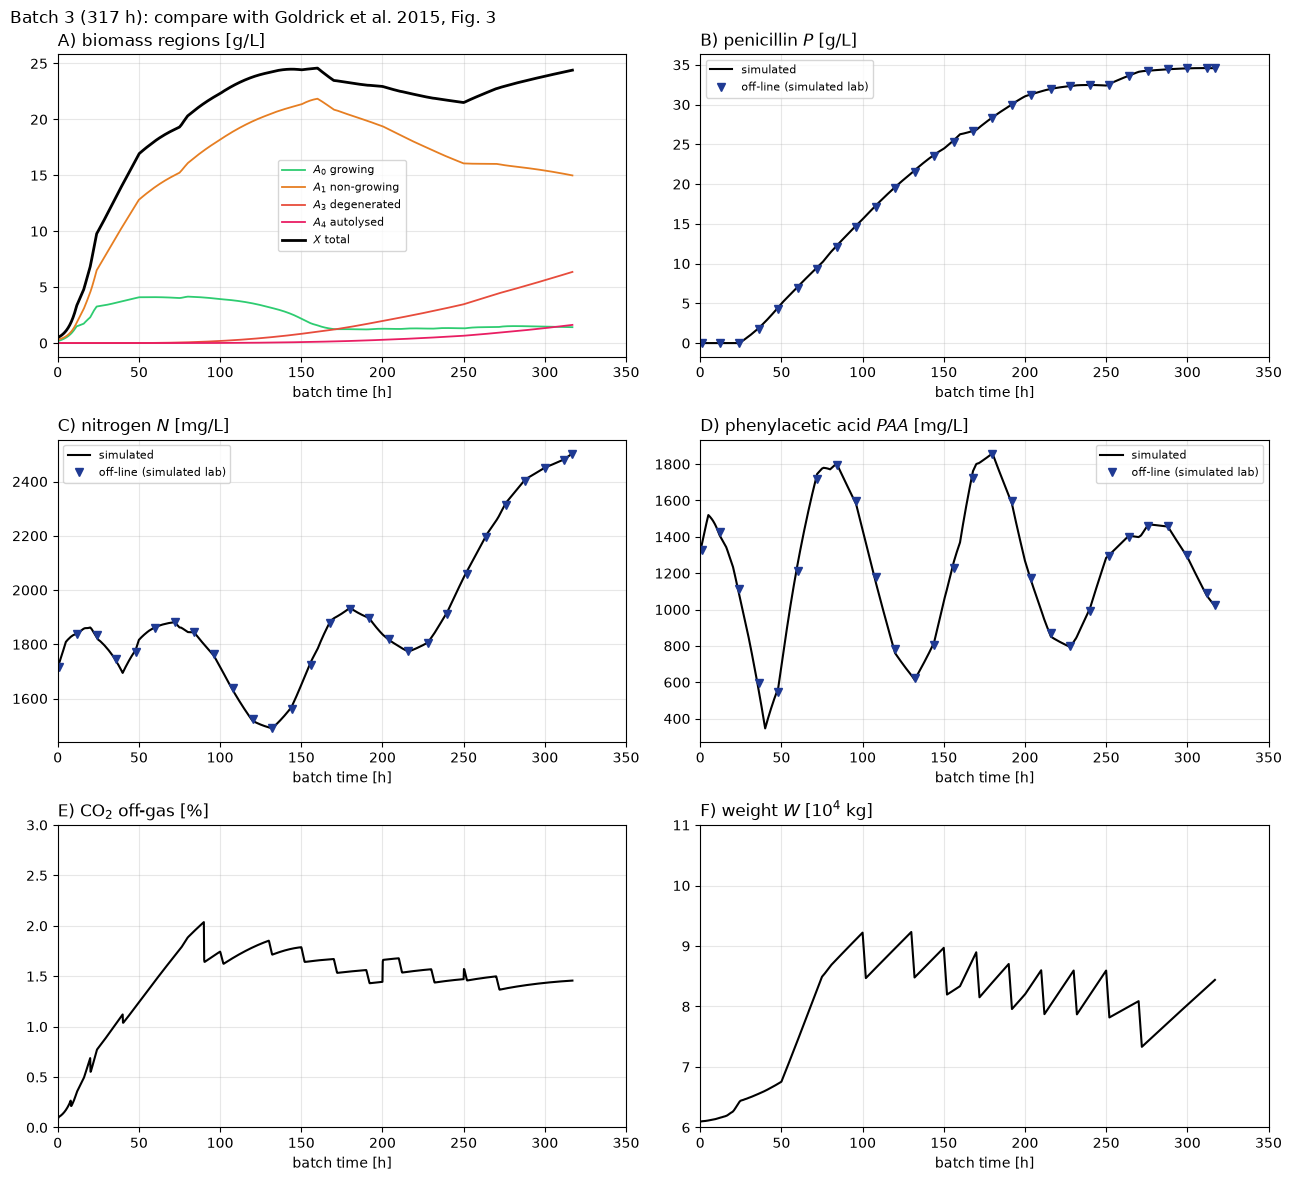

In [3]:
r = results["Batch 3"]
t = r.time
fig, axes = plt.subplots(3, 2, figsize=(13, 12))

ax = axes[0, 0]
for name, label, color in [
    ("a0", "$A_0$ growing", "#2ecc71"),
    ("a1", "$A_1$ non-growing", "#e67e22"),
    ("a3", "$A_3$ degenerated", "#e74c3c"),
    ("a4", "$A_4$ autolysed", "#e91e63"),
    ("X", "$X$ total", "k"),
]:
    ax.plot(t, r[name], color=color, lw=2 if name == "X" else 1.3, label=label)
ax.set(title="A) biomass regions [g/L]")


def with_lab(ax, name, lab, title, unit):
    ax.plot(t, r[name], color="k", label="simulated")
    keep = ~np.isnan(r[lab])
    ax.plot(t[keep], r[lab][keep], "v", color="#1f3a93", ms=6, label="off-line (simulated lab)")
    ax.set(title=f"{title} [{unit}]")


with_lab(axes[0, 1], "P", "P_offline", "B) penicillin $P$", "g/L")
with_lab(axes[1, 0], "NH3", "NH3_offline", "C) nitrogen $N$", "mg/L")
with_lab(axes[1, 1], "PAA", "PAA_offline", "D) phenylacetic acid $PAA$", "mg/L")
axes[2, 0].plot(t, r["CO2outgas"], color="k")
axes[2, 0].set(title="E) CO$_2$ off-gas [%]", ylim=(0, 3))
axes[2, 1].plot(t, r["Wt"] / 1e4, color="k")
axes[2, 1].set(title="F) weight $W$ [10$^4$ kg]", ylim=(6, 11))
for ax in axes.flat:
    ax.set(xlim=(0, 350), xlabel="batch time [h]")
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=8)
fig.suptitle("Batch 3 (317 h): compare with Goldrick et al. 2015, Fig. 3", x=0.01, ha="left")
fig.tight_layout()
plt.show()

Values of the paper's Fig. 3 (simulation driven by the plant records) read from the figure, against ours:

In [4]:
def first_time(mask):
    return float(t[np.argmax(mask)])


after_peak = t > t[np.argmax(r["Wt"])]
features = pd.DataFrame(
    {
        "paper, Fig. 3 (approx.)": [
            "~27.5 g/L at ~150 h",
            "declines to ~24 at 317 h",
            "~38 g/L at ~250 h",
            "1950 peak early, min ~520 at ~190 h",
            "mostly 600-1600 mg/L",
            "~1.5-2.1 %",
            "62 t -> ~108 t at ~120 h",
            "saw-tooth ~95-107 t to ~300 h",
        ],
        "Penicillium": [
            f"{r['X'].max():.1f} g/L at {t[np.argmax(r['X'])]:.0f} h",
            f"{r['X'][-1]:.1f} g/L at {t[-1]:.0f} h",
            f"{r['P'].max():.1f} g/L at {t[np.argmax(r['P'])]:.0f} h",
            f"{r['NH3'].max():.0f} peak, min {r['NH3'].min():.0f} at {t[np.argmin(r['NH3'])]:.0f} h",
            f"{np.percentile(r['PAA'], 5):.0f}-{np.percentile(r['PAA'], 95):.0f} mg/L (5-95 %)",
            "{:.1f}-{:.1f} % (after 50 h)".format(*np.percentile(r["CO2outgas"][t > 50], [5, 95])),
            f"{r['Wt'][0] / 1e3:.0f} t -> {r['Wt'].max() / 1e3:.0f} t at {t[np.argmax(r['Wt'])]:.0f} h",
            f"{r['Wt'][after_peak].min() / 1e3:.0f}-{r['Wt'][after_peak].max() / 1e3:.0f} t after the peak",
        ],
    },
    index=["biomass peak", "biomass at harvest", "penicillin peak", "nitrogen", "PAA", "CO2 off-gas",
           "weight rise", "weight after the peak"],
)  # fmt: skip
features

,"paper, Fig. 3 (approx.)",Penicillium
biomass peak,~27.5 g/L at ~150 h,24.6 g/L at 160 h
biomass at harvest,declines to ~24 at 317 h,24.4 g/L at 317 h
penicillin peak,~38 g/L at ~250 h,34.6 g/L at 311 h
nitrogen,"1950 peak early, min ~520 at ~190 h","2504 peak, min 1490 at 132 h"
PAA,mostly 600-1600 mg/L,626-1789 mg/L (5-95 %)
CO2 off-gas,~1.5-2.1 %,1.4-1.8 % (after 50 h)
weight rise,62 t -> ~108 t at ~120 h,61 t -> 92 t at 130 h
weight after the peak,saw-tooth ~95-107 t to ~300 h,73-92 t after the peak


**Compared with the paper's Fig. 3.** The biomass behaves as in the paper: it rises fast, peaks around 150 h and
then declines (the paper attributes this to the age-dependent differentiation term $K_{diff}$, Eq. 10); the
non-growing region $A_1$ dominates, and degenerated and autolysed regions build up late. Penicillin rises almost
linearly to the mid-30s g/L, PAA stays in the operating band, CO₂ in the off-gas levels off below ~2 %, and the
weight shows the repeated fed-batch saw-tooth.

Two outputs differ in level, both tied to inputs we do not have:

* **Weight.** The plant discharged by weight to stay at ~95-107 t up to ~300 h; IndPenSim's standard recipe
  discharges 2 h at fixed times (the last at 272 h) and feeds less, so the vessel runs lighter.
* **Nitrogen.** In the paper nitrogen is consumed down to ~520 mg/L; here it stays above ~1500 mg/L, because the
  PAA feed also supplies nitrogen. The paper notes that nitrogen and PAA consumption were highly sensitive to
  the nitrogen and PAA content of that feed, and that it assumed different feed compositions for each batch
  (Table 2) to fit the records; those per-batch values are not published.

**Why the PAA feed matters in long batches.** With IndPenSim's fixed recipe instead of operator dosing, PAA runs
out in batch 3 and penicillin production stops:

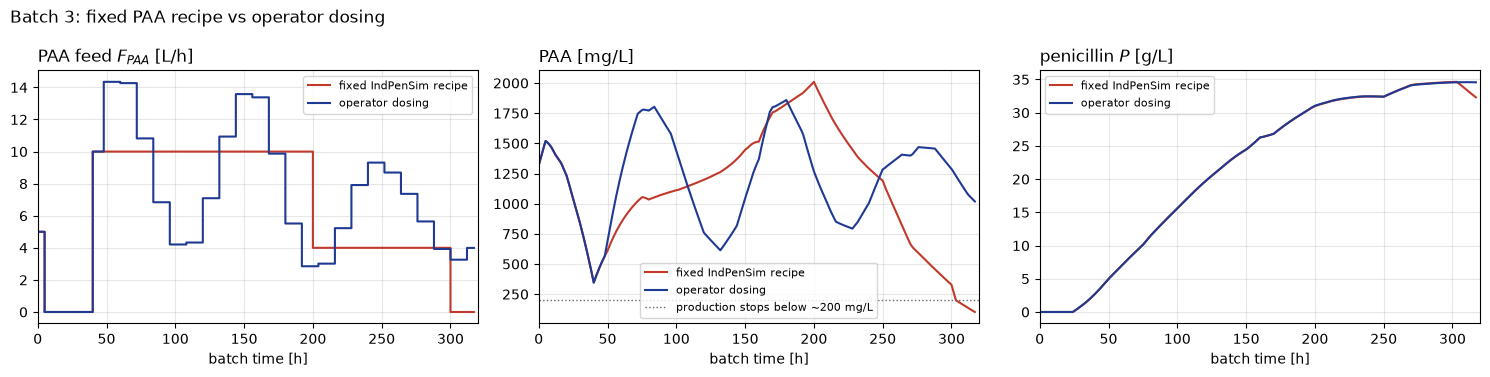

In [5]:
row = TABLE3.loc["Batch 3"]
fixed = run_batch(3, row["t [h]"], row["mu_X_max [1/h]"], row["mu_P_max [1/h]"], operator_paa=False)
operated = results["Batch 3"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for res, label, color in [(fixed, "fixed IndPenSim recipe", "#c0392b"), (operated, "operator dosing", "#1f3a93")]:
    axes[0].plot(res.time, res["Fpaa"], color=color, drawstyle="steps-pre", label=label)
    axes[1].plot(res.time, res["PAA"], color=color, label=label)
    axes[2].plot(res.time, res["P"], color=color, label=label)
axes[1].axhline(200, color="0.4", ls=":", lw=1, label="production stops below ~200 mg/L")
for ax, title in zip(axes, ["PAA feed $F_{PAA}$ [L/h]", "PAA [mg/L]", "penicillin $P$ [g/L]"], strict=True):
    ax.set(title=title, xlabel="batch time [h]", xlim=(0, 320))
    ax.legend(fontsize=8)
fig.suptitle("Batch 3: fixed PAA recipe vs operator dosing", x=0.01, ha="left")
fig.tight_layout()
plt.show()

With the fixed recipe PAA falls below ~200 mg/L after ~270 h, where the model's production term switches off,
and the final titre drops by about 4 g/L.

## 3. Fig. 4: four batches

The paper's Fig. 4 shows batches 1, 3, 8 and 10: sugar feed $F_s$, soybean oil feed $F_{oil}$, penicillin and
substrate. Here the feeds are the standard recipe for all four; in the plant they were set by the operators.

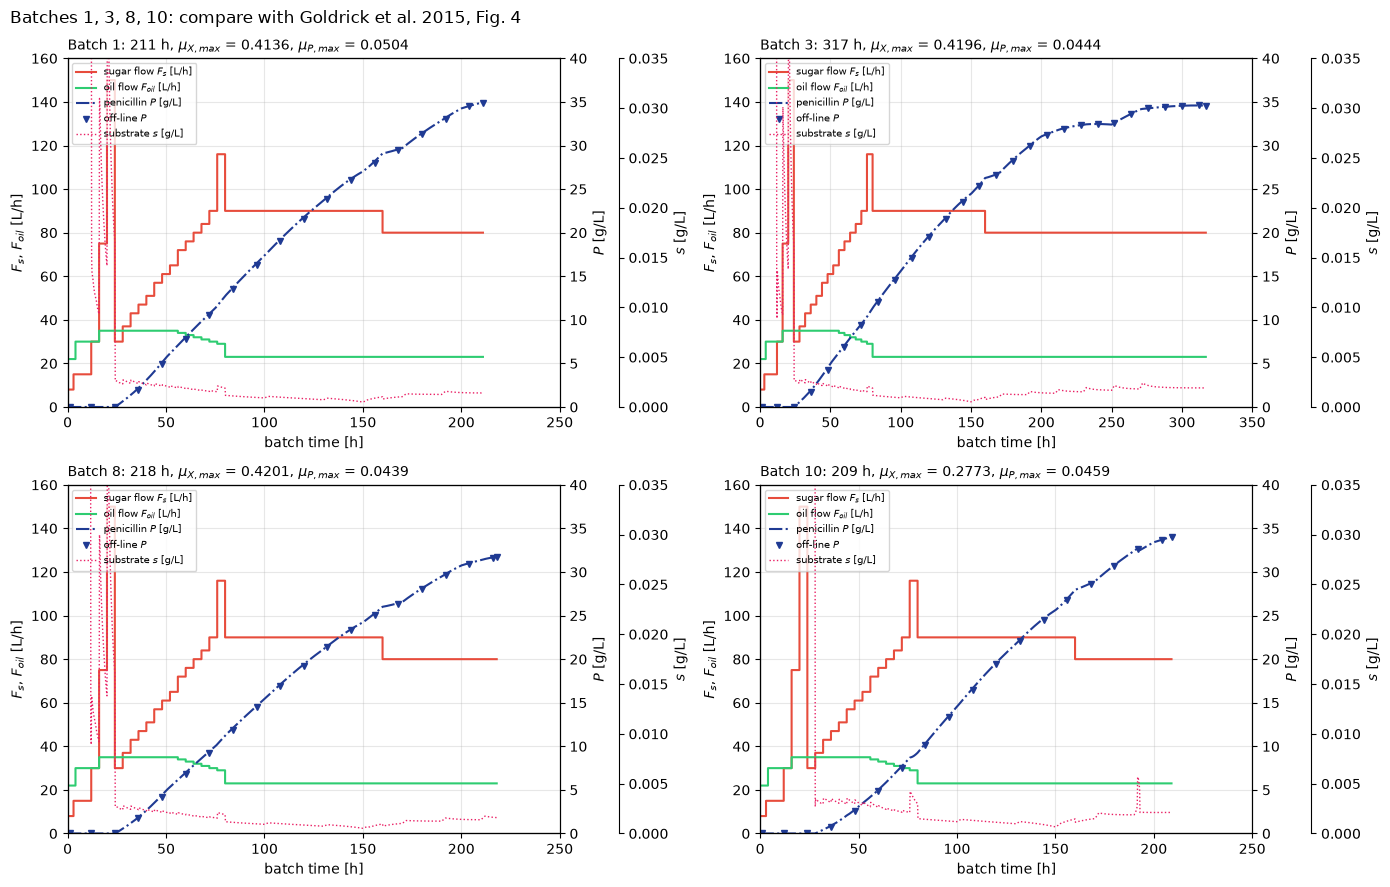

,"paper: final off-line P, read from Fig. 4 [g/L]",Penicillium: final P [g/L]
Batch 1,34,35.0
Batch 3,34,34.6
Batch 8,31,31.8
Batch 10,28,34.0


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, name in zip(axes.flat, ["Batch 1", "Batch 3", "Batch 8", "Batch 10"], strict=True):
    r = results[name]
    ax.plot(r.time, r["Fs"], color="#e74c3c", drawstyle="steps-pre", label="sugar flow $F_s$ [L/h]")
    ax.plot(r.time, r["Foil"], color="#2ecc71", drawstyle="steps-pre", label="oil flow $F_{oil}$ [L/h]")
    ax.set(
        ylim=(0, 160),
        xlim=(0, 350 if name == "Batch 3" else 250),
        xlabel="batch time [h]",
        ylabel="$F_s$, $F_{oil}$ [L/h]",
    )
    axp = ax.twinx()
    axp.plot(r.time, r["P"], color="#1f3a93", ls="-.", label="penicillin $P$ [g/L]")
    keep = ~np.isnan(r["P_offline"])
    axp.plot(r.time[keep], r["P_offline"][keep], "v", color="#1f3a93", ms=5, label="off-line $P$")
    axp.set(ylim=(0, 40), ylabel="$P$ [g/L]")
    axs = ax.twinx()
    axs.spines["right"].set_position(("axes", 1.12))
    axs.plot(r.time, r["S"], color="#e91e63", ls=":", lw=1, label="substrate $s$ [g/L]")
    axs.set(ylim=(0, 0.035), ylabel="$s$ [g/L]")
    axs.grid(False)
    axp.grid(False)
    lines = [h for a in (ax, axp, axs) for h in a.get_legend_handles_labels()[0]]
    labels = [lab for a in (ax, axp, axs) for lab in a.get_legend_handles_labels()[1]]
    ax.legend(lines, labels, fontsize=7, loc="upper left")
    row = TABLE3.loc[name]
    ax.set_title(
        f"{name}: {row['t [h]']} h, $\\mu_{{X,max}}$ = {row['mu_X_max [1/h]']}, "
        f"$\\mu_{{P,max}}$ = {row['mu_P_max [1/h]']}",
        fontsize=10,
    )
fig.suptitle("Batches 1, 3, 8, 10: compare with Goldrick et al. 2015, Fig. 4", x=0.01, ha="left")
fig.tight_layout()
plt.show()

read_from_fig4 = {"Batch 1": 34, "Batch 3": 34, "Batch 8": 31, "Batch 10": 28}
pd.DataFrame({
    "paper: final off-line P, read from Fig. 4 [g/L]": read_from_fig4,
    "Penicillium: final P [g/L]": {k: round(results[k]["P"][-1], 1) for k in read_from_fig4},
})  # fmt: skip

**Compared with the paper's Fig. 4.** Both show the sharp sugar-feed peak at ~20 h, which keeps substrate in
excess during rapid growth, followed by low substrate (a few mg/L) in the production phase. Penicillin starts
after ~25 h and rises almost linearly. The final titres of batches 1, 3 and 8 are within ~1 g/L of the paper's,
even though the plant's sugar feed was higher after 80 h (up to 140-150 L/h against 80-116 L/h in the recipe).
Batch 10 ends ~6 g/L higher here: the paper lists it as limited by nitrogen (NH₃), and nitrogen never runs low in
these simulations (see Fig. 3 above), so that limitation cannot appear.

## 4. Fig. 5: aeration, pressure, water, oil, dissolved oxygen and viscosity

The paper's Fig. 5 shows one batch of about 210 h without naming it; batch 1 (211 h) is the closest. The paper
notes that dissolved oxygen and viscosity are the least accurate outputs, because the simulated viscosity
differs from the off-line measurements early in the batch.

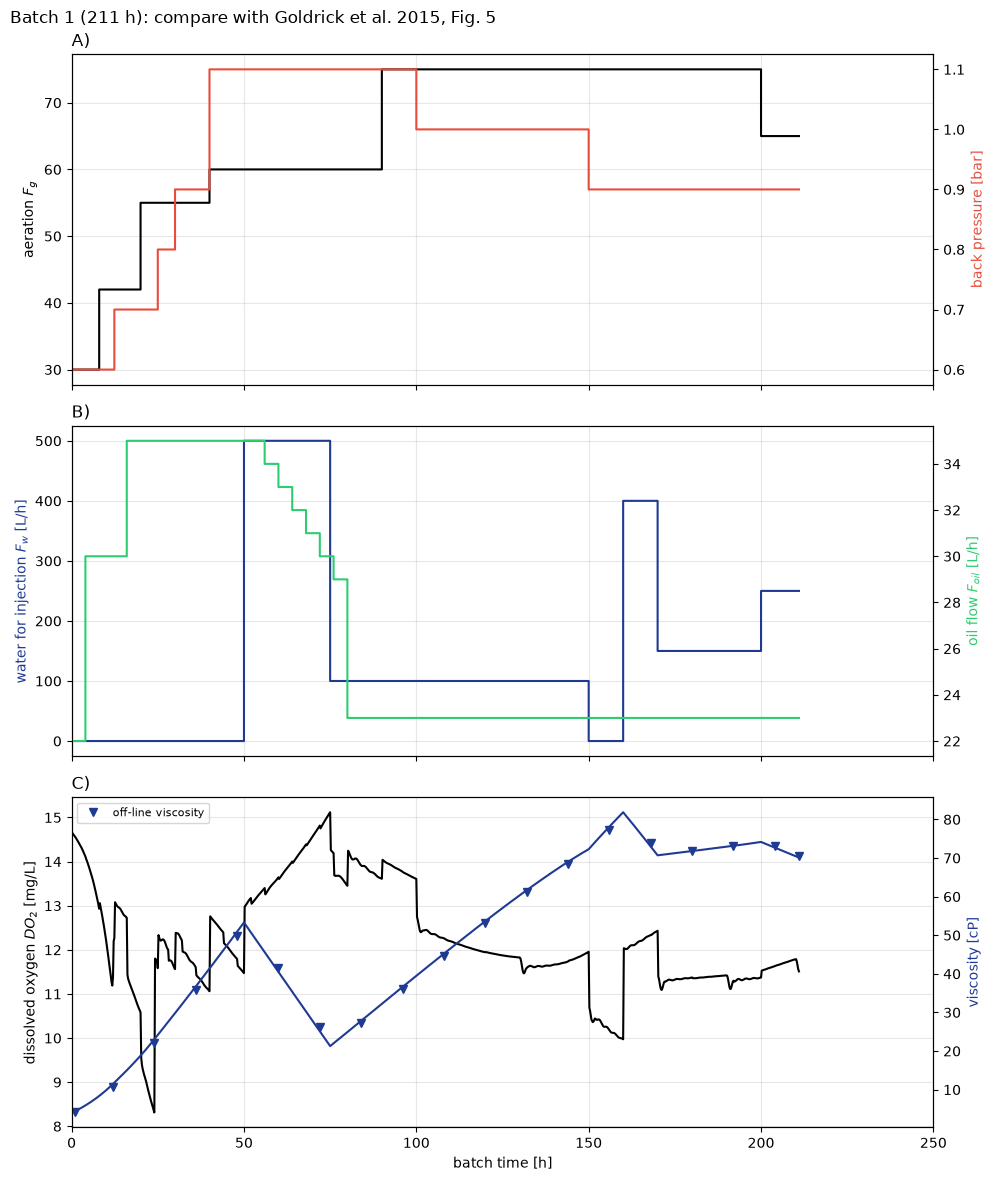

In [7]:
r = results["Batch 1"]
fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)
pairs = [
    (("Fg", "aeration $F_g$", "k"), ("pressure", "back pressure [bar]", "#e74c3c"), "A)"),
    (("Fw", "water for injection $F_w$ [L/h]", "#1f3a93"), ("Foil", "oil flow $F_{oil}$ [L/h]", "#2ecc71"), "B)"),
    (("DO2", "dissolved oxygen $DO_2$ [mg/L]", "k"), ("Viscosity", "viscosity [cP]", "#1f3a93"), "C)"),
]
for ax, ((left, left_label, left_color), (right, right_label, right_color), tag) in zip(axes, pairs, strict=True):
    ax.plot(r.time, r[left], color=left_color, drawstyle="steps-pre" if left != "DO2" else "default")
    ax.set_ylabel(left_label, color=left_color)
    ax2 = ax.twinx()
    ax2.plot(r.time, r[right], color=right_color, drawstyle="steps-pre" if right != "Viscosity" else "default")
    if right == "Viscosity":
        keep = ~np.isnan(r["Viscosity_offline"])
        ax2.plot(r.time[keep], r["Viscosity_offline"][keep], "v", color=right_color, ms=6, label="off-line viscosity")
        ax2.legend(loc="upper left", fontsize=8)
    ax2.set_ylabel(right_label, color=right_color)
    ax2.grid(False)
    ax.set_title(tag)
axes[-1].set(xlabel="batch time [h]", xlim=(0, 250))
fig.suptitle("Batch 1 (211 h): compare with Goldrick et al. 2015, Fig. 5", x=0.01, ha="left")
fig.tight_layout()
plt.show()

**Compared with the paper's Fig. 5.** Aeration and back pressure follow the same staircase (aeration 30 -> ~75,
pressure 0.6 -> 1.1 bar over the first 100 h), oil is fed at 22-35 L/h, and water is added in a few large
blocks (the plant's water additions were at other times). Dissolved oxygen stays between ~9 and 16 mg/L, as in
the paper. The simulated viscosity rises to a first peak around 50 h, dips when water is added, and then
climbs to ~70-80 cP: the same path as the paper's simulated viscosity, which the plant's off-line viscosity did
not follow early in the batch (the limitation the paper discusses).

## 5. Table 4: which parameters matter most

The paper's sensitivity analysis (Table 4) ranks $\mu_{P,max}$ as by far the most influential parameter for
penicillin, and notes that $\mu_{X,max}$, although it varies a lot between batches, has little effect on biomass.
We check both with a one-at-a-time test on batch 3: each parameter is raised by 10 % and we record the relative
change of the final penicillin and of the peak biomass. (The paper's measure $\delta^{msqr}$ is computed
differently, so only the ranking is comparable.)

In [8]:
row = TABLE3.loc["Batch 3"]
nominal = {"mu_x_max": row["mu_X_max [1/h]"], "mu_p_max": row["mu_P_max [1/h]"]}
nominal.update({k: v for k, v in Simulator.initial_conditions(3).items() if k in ("alpha_kla", "PAA_c", "N_conc_paa")})
params = ["mu_p_max", "mu_x_max", "alpha_kla", "PAA_c", "N_conc_paa"]


def run_with(values):
    values = dict(values)
    return run_batch(3, row["t [h]"], values.pop("mu_x_max"), values.pop("mu_p_max"), **values)


ref = run_with(nominal)
perturbed = [run_with({**nominal, p: 1.1 * nominal[p]}) for p in params]
sensitivity = pd.DataFrame(
    {
        "final penicillin": [100 * (r["P"][-1] / ref["P"][-1] - 1) for r in perturbed],
        "peak biomass": [100 * (r["X"].max() / ref["X"].max() - 1) for r in perturbed],
    },
    index=pd.Index(params, name="+10 % on"),
).round(1)
sensitivity.columns = [f"change of {c} [%]" for c in sensitivity.columns]
sensitivity

,change of final penicillin [%],change of peak biomass [%]
+10 % on,,
mu_p_max,6.9,-2.8
mu_x_max,-1.6,1.1
alpha_kla,0.0,-0.0
PAA_c,0.2,0.1
N_conc_paa,0.0,0.0


As in Table 4, the maximum specific production rate $\mu_{P,max}$ has by far the largest effect on penicillin,
and the maximum specific growth rate $\mu_{X,max}$ changes the peak biomass only slightly.

## 6. Summary

* The simulated profiles of Figs. 3-5 have the same shapes, timings and ranges as the paper's: biomass peaking
  around 150 h and then declining, near-linear penicillin production to 30-40 g/L, nitrogen and PAA in the
  reported ranges, the repeated fed-batch weight profile, the aeration/pressure staircase, and the viscosity
  pattern discussed as a limitation.
* The sensitivity ranking of Table 4 for penicillin ($\mu_{P,max}$ first) and the weak effect of $\mu_{X,max}$ on
  biomass are reproduced.
* A point-by-point comparison with the paper's figures is not possible: the paper drove each simulation with the
  plant's recorded feeds, aeration, pressure and discharges, which are not published. Differences in levels
  (for example the heavier plant vessel and its later discharges) come from those inputs.